In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.numerics import (euler_hourly, exact_hourly, solve_ivp_hourly, forcing_from_power,
                          amplification_factor, amplification_factor_implicit, time_it)
from src.config import BATTERY_SELF_DISCHARGE as K

# Test day (hour-ending 01:00 to 24:00): charge 2 kW for four hours, discharge 1.5 kW in the evening
day_power = np.zeros(24)
day_power[9:13] = 2.0      # hour-ending 10:00 to 13:00
day_power[18:22] = -1.5    # hour-ending 19:00 to 22:00
F = forcing_from_power(day_power)
E0 = 2.0                   # starting energy (kWh)

exact = exact_hourly(E0, F, K)
print("Exact energy at the end of the day:", round(exact[-1], 6), "kWh")

Exact energy at the end of the day: 3.144706 kWh


In [2]:
STEPS_MIN = [60, 30, 15, 5, 1]            # step sizes in minutes
rows = []
for m in STEPS_MIN:
    sub = 60 // m                          # sub-steps per hour
    ex = euler_hourly(E0, F, K, sub, "explicit")[-1]
    im = euler_hourly(E0, F, K, sub, "implicit")[-1]
    rows.append({"Step (min)": m, "Explicit final E (kWh)": ex, "Implicit final E (kWh)": im,
                 "Explicit error": abs(ex - exact[-1]), "Implicit error": abs(im - exact[-1])})
table = pd.DataFrame(rows).set_index("Step (min)")

slope_ex = np.polyfit(np.log(STEPS_MIN), np.log(table["Explicit error"]), 1)[0]
slope_im = np.polyfit(np.log(STEPS_MIN), np.log(table["Implicit error"]), 1)[0]
print(f"Fitted convergence order: explicit {slope_ex:.2f}, implicit {slope_im:.2f}")
table.round(6)

Fitted convergence order: explicit 1.00, implicit 1.00


,Explicit final E (kWh),Implicit final E (kWh),Explicit error,Implicit error
Step (min),,,,
60,3.145243,3.144170,0.000537,0.000536
30,3.144975,3.144438,0.000268,0.000268
15,3.144841,3.144572,0.000134,0.000134
5,3.144751,3.144662,0.000045,0.000045
1,3.144715,3.144698,0.000009,0.000009


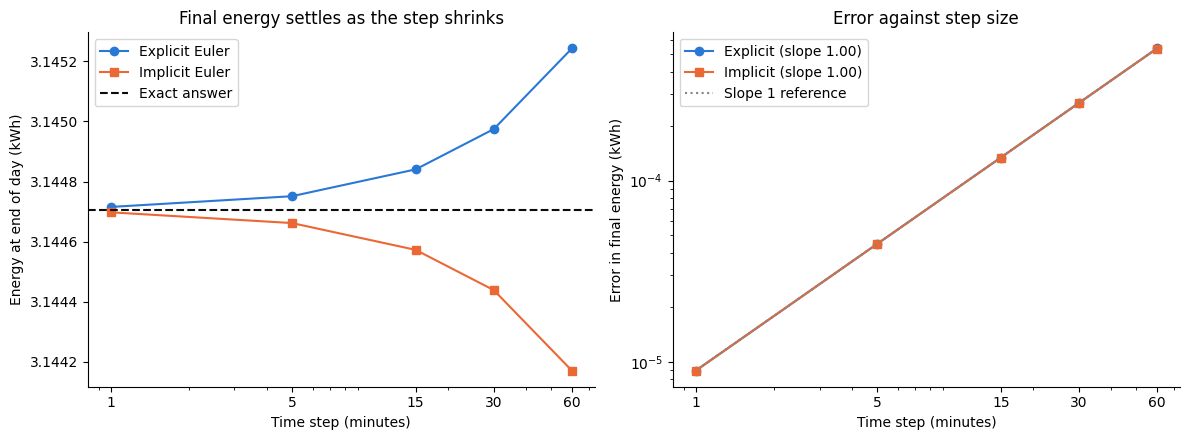

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(STEPS_MIN, table["Explicit final E (kWh)"], "o-", color="#2a78d6", label="Explicit Euler")
axes[0].plot(STEPS_MIN, table["Implicit final E (kWh)"], "s-", color="#eb6834", label="Implicit Euler")
axes[0].axhline(exact[-1], color="#0b0b0b", ls="--", label="Exact answer")
axes[0].set_title("Final energy settles as the step shrinks")
axes[0].set_ylabel("Energy at end of day (kWh)")

axes[1].loglog(STEPS_MIN, table["Explicit error"], "o-", color="#2a78d6", label=f"Explicit (slope {slope_ex:.2f})")
axes[1].loglog(STEPS_MIN, table["Implicit error"], "s-", color="#eb6834", label=f"Implicit (slope {slope_im:.2f})")
ref = table["Explicit error"].iloc[0] * np.array(STEPS_MIN) / STEPS_MIN[0]
axes[1].loglog(STEPS_MIN, ref, color="#898781", ls=":", label="Slope 1 reference")
axes[1].set_title("Error against step size")
axes[1].set_ylabel("Error in final energy (kWh)")

for ax in axes:
    ax.set_xlabel("Time step (minutes)")
    ax.set_xscale("log")
    ax.set_xticks(STEPS_MIN)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.legend()
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(ROOT / "results" / "fig_convergence.png", dpi=150)
plt.show()

In [4]:
n = 5
cmp = pd.DataFrame({
    "Exact": exact_hourly(5.0, np.zeros(n), 2.5),
    "Explicit Euler": euler_hourly(5.0, np.zeros(n), 2.5, 1, "explicit"),
    "Implicit Euler": euler_hourly(5.0, np.zeros(n), 2.5, 1, "implicit"),
}, index=range(1, n + 1))
print("Large leak rate k = 2.5 per hour, 1-hour step (k*dt = 2.5):")
print("Explicit factor:", amplification_factor(2.5, 1.0), "| Implicit factor:", round(amplification_factor_implicit(2.5, 1.0), 3))
cmp.round(3)

Large leak rate k = 2.5 per hour, 1-hour step (k*dt = 2.5):
Explicit factor: -1.5 | Implicit factor: 0.286


,Exact,Explicit Euler,Implicit Euler
1,0.410,-7.500,1.429
2,0.034,11.250,0.408
3,0.003,-16.875,0.117
4,0.000,25.312,0.033
5,0.000,-37.969,0.010


In [5]:
methods = {
    "Explicit Euler, 1 h step": lambda: euler_hourly(E0, F, K, 1),
    "Explicit Euler, 1 min step": lambda: euler_hourly(E0, F, K, 60),
    "Implicit Euler, 1 h step": lambda: euler_hourly(E0, F, K, 1, "implicit"),
    "solve_ivp BDF": lambda: solve_ivp_hourly(E0, F, K, "BDF"),
    "solve_ivp Radau": lambda: solve_ivp_hourly(E0, F, K, "Radau"),
    "solve_ivp LSODA": lambda: solve_ivp_hourly(E0, F, K, "LSODA"),
}
rows = []
for name, fn in methods.items():
    err = np.abs(fn() - exact).max()
    sec = time_it(fn, repeats=3)
    rows.append({"Method": name, "Max error over the day (kWh)": err,
                 "Time for 1 day (ms)": 1000 * sec, "Estimated time for 1 year (s)": 365 * sec})
pd.set_option("display.float_format", "{:.3g}".format)
pd.DataFrame(rows).set_index("Method")


,Max error over the day (kWh),Time for 1 day (ms),Estimated time for 1 year (s)
Method,,,
"Explicit Euler, 1 h step",0.00377,0.022,0.00803
"Explicit Euler, 1 min step",6.28e-05,0.4,0.146
"Implicit Euler, 1 h step",0.00376,0.0156,0.00568
solve_ivp BDF,3.36e-10,101,36.8
solve_ivp Radau,2.27e-13,39.8,14.5
solve_ivp LSODA,3.63e-09,7.13,2.6


DRAFT: The battery energy equation was solved with the explicit Euler method and compared against backward Euler, three solve_ivp methods (BDF, Radau and LSODA, with relative tolerance 10⁻¹⁰) and the analytical solution, which exists because the power is constant within each hour. Reducing the time step from 60 to 1 minute reduced the error in the end-of-day energy from 5.4 × 10⁻⁴ kWh to 8.9 × 10⁻⁶ kWh, with a fitted convergence order of 1.00 for both Euler variants, as expected for first-order methods. At the hourly step used in the simulation, the error is 0.005% of battery capacity. The stiff solvers provided no accuracy benefit that mattered for the problem and were between two and four orders of magnitude slower per simulated year, so an hourly explicit Euler step was adopted.